# Build Meisner Scenario — All Input Files

Generates **all simulation input files** for the Meisner et al. (2025) battlefield
scenario from a single parametric configuration cell.

**Topology (configurable in Cell 1)**
- Variable number of brigades, each with a configurable number of battalions
- Variable Role-1 MTFs per brigade (placed evenly across brigade width)
- Variable Role-2 MTFs per brigade (placed evenly across brigade width)
- 1 CCP per battalion, 1 AXP per brigade

**Default: 3 brigades × 3 battalions, 3 R1/brigade, 3 R2/brigade (Meisner et al. 2025)**

**Output files** (written to `data/single_run/input/`):

| Sub-path | Description |
|---|---|
| `components/distances/distance_matrix_{SUFFIX}.xlsx` | Euclidean distance matrix |
| `components/distances/coordinates_{SUFFIX}.xlsx` | Coordinate reference |
| `components/facilities/facilities_{SUFFIX}.xlsx` | CCP / R1 / R2 facilities |
| `components/units/units_{SUFFIX}.xlsx` | DCR, PEC, DCS service units |
| `components/AXPs/axp_{SUFFIX}.xlsx` | Ambulance exchange points |
| `components/ambulances/amb_{SUFFIX}.xlsx` | Ambulance fleet |
| `components/c2/c2_{SUFFIX}.xlsx` | C2 nodes |
| `policy_matrixes/…/facility_eligibility_{SUFFIX}_strict/loose.xlsx` | Facility routing policy |
| `policy_matrixes/…/ambulance_eligibility_{SUFFIX}_strict/loose.xlsx` | Ambulance routing policy |


In [84]:
import pathlib, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

## Cell 1 — Configuration

Edit the parameters below to change geometry, order of battle, and logistics.
All downstream cells derive from these values automatically.

In [106]:
# ── Facility counts ────────────────────────────────────────────────────────────
N_CCP = 15   # must equal N_R1: one CCP feeds exactly one R1
N_R1  = 15
N_AXP =  3
N_R2  = 12

# ── Geometry (km) ──────────────────────────────────────────────────────────────
FRONTAGE_KM = 90.0
Y_CCP  =  4.0
Y_R1   =  7.0
Y_AXP  = 12.0
Y_R2   = 15.0

# ── Unit service-time parameters ───────────────────────────────────────────────
DCS_CAPACITY                   = 2
DCS_MILD_MEAN,   DCS_MILD_STD  = 93.9,  41.3
DCS_SEVERE_MEAN, DCS_SEVERE_STD = 180.0, 83.0
DCR_CAPACITY, DCR_MIN, DCR_MAX = 2, 27, 28
PEC_CAPACITY, PEC_MIN, PEC_MAX = 2, 27, 28

# ── Ambulance parameters ───────────────────────────────────────────────────────
CCP_AMBS_PER_R1   = 3    # CCP→R1 ambulances, stationed at the R1
R1R2_AMBS_PER_AXP = 4    # R1→R2 ambulances, stationed at the AXP
AMB_CAPACITY      = 5
AMB_SPEED_KMH     = 30

# ── Casualty rates (per soldier per day) ───────────────────────────────────────
TOTAL_PAR     = 18800
CAS_BCAS_RATE = 0.023
CAS_DNBI_RATE = 0.0013

# ── Output ─────────────────────────────────────────────────────────────────────
OUT_BASE = pathlib.Path("data/single_run/input")
SUFFIX   = "meisner"

## Cell 2 — Build facility coordinates

In [107]:
nodes        = []
ccp_r1_pairs = []   # [(ccp_id, r1_id)] — index-matched pairs

# CCPs and R1s — placed at the same x, paired by index
for i in range(1, N_CCP + 1):
    x = (i - 0.5) * FRONTAGE_KM / N_CCP
    nodes.append({"facility_id": f"ccp_{i}", "facility_type": "CCP",   "x": x, "y": Y_CCP})
    nodes.append({"facility_id": f"r1_{i}",  "facility_type": "Role1", "x": x, "y": Y_R1})
    ccp_r1_pairs.append((f"ccp_{i}", f"r1_{i}"))

# AXPs
for i in range(1, N_AXP + 1):
    x = (i - 0.5) * FRONTAGE_KM / N_AXP
    nodes.append({"facility_id": f"axp_{i}", "facility_type": "AXP", "x": x, "y": Y_AXP})

# R2s
for i in range(1, N_R2 + 1):
    x = (i - 0.5) * FRONTAGE_KM / N_R2
    nodes.append({"facility_id": f"r2_{i}", "facility_type": "Role2", "x": x, "y": Y_R2})

fac_df = pd.DataFrame(nodes)

# Assign each R1 / R2 to its nearest AXP (used for strict eligibility and AXP routing)
axp_xs    = {f"axp_{i}": (i - 0.5) * FRONTAGE_KM / N_AXP for i in range(1, N_AXP + 1)}
r1_to_axp = {f"r1_{i}": min(axp_xs, key=lambda a: abs(axp_xs[a] - (i - 0.5) * FRONTAGE_KM / N_R1))
             for i in range(1, N_R1 + 1)}
r2_to_axp = {f"r2_{i}": min(axp_xs, key=lambda a: abs(axp_xs[a] - (i - 0.5) * FRONTAGE_KM / N_R2))
             for i in range(1, N_R2 + 1)}
axp_to_r1s = {}
for r1, axp in r1_to_axp.items():
    axp_to_r1s.setdefault(axp, []).append(r1)

print(f"Map nodes: {len(fac_df)}  (CCP={N_CCP}, R1={N_R1}, AXP={N_AXP}, R2={N_R2})")
print(f"CCP→R1 pairs: {ccp_r1_pairs}")
print(f"R1→AXP: {r1_to_axp}")

Map nodes: 45  (CCP=15, R1=15, AXP=3, R2=12)
CCP→R1 pairs: [('ccp_1', 'r1_1'), ('ccp_2', 'r1_2'), ('ccp_3', 'r1_3'), ('ccp_4', 'r1_4'), ('ccp_5', 'r1_5'), ('ccp_6', 'r1_6'), ('ccp_7', 'r1_7'), ('ccp_8', 'r1_8'), ('ccp_9', 'r1_9'), ('ccp_10', 'r1_10'), ('ccp_11', 'r1_11'), ('ccp_12', 'r1_12'), ('ccp_13', 'r1_13'), ('ccp_14', 'r1_14'), ('ccp_15', 'r1_15')]
R1→AXP: {'r1_1': 'axp_1', 'r1_2': 'axp_1', 'r1_3': 'axp_1', 'r1_4': 'axp_1', 'r1_5': 'axp_1', 'r1_6': 'axp_2', 'r1_7': 'axp_2', 'r1_8': 'axp_2', 'r1_9': 'axp_2', 'r1_10': 'axp_2', 'r1_11': 'axp_3', 'r1_12': 'axp_3', 'r1_13': 'axp_3', 'r1_14': 'axp_3', 'r1_15': 'axp_3'}


In [108]:
print(fac_df[["facility_id","facility_type","x","y"]].to_string(index=False))

facility_id facility_type     x    y
      ccp_1           CCP  3.00  4.0
       r1_1         Role1  3.00  7.0
      ccp_2           CCP  9.00  4.0
       r1_2         Role1  9.00  7.0
      ccp_3           CCP 15.00  4.0
       r1_3         Role1 15.00  7.0
      ccp_4           CCP 21.00  4.0
       r1_4         Role1 21.00  7.0
      ccp_5           CCP 27.00  4.0
       r1_5         Role1 27.00  7.0
      ccp_6           CCP 33.00  4.0
       r1_6         Role1 33.00  7.0
      ccp_7           CCP 39.00  4.0
       r1_7         Role1 39.00  7.0
      ccp_8           CCP 45.00  4.0
       r1_8         Role1 45.00  7.0
      ccp_9           CCP 51.00  4.0
       r1_9         Role1 51.00  7.0
     ccp_10           CCP 57.00  4.0
      r1_10         Role1 57.00  7.0
     ccp_11           CCP 63.00  4.0
      r1_11         Role1 63.00  7.0
     ccp_12           CCP 69.00  4.0
      r1_12         Role1 69.00  7.0
     ccp_13           CCP 75.00  4.0
      r1_13         Role1 75.00  7.0
 

## Cell 3 — Compute Euclidean distance matrix

In [109]:
ids  = fac_df["facility_id"].tolist()
coords = fac_df[["x", "y"]].values   # shape (N, 2)

N = len(ids)
dist = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        dist[i, j] = np.linalg.norm(coords[i] - coords[j])

dist_df = pd.DataFrame(dist, index=ids, columns=ids)

# Show a rounded preview
dist_df.round(2)

,ccp_1,r1_1,ccp_2,r1_2,ccp_3,r1_3,ccp_4,r1_4,ccp_5,r1_5,...,r2_3,r2_4,r2_5,r2_6,r2_7,r2_8,r2_9,r2_10,r2_11,r2_12
ccp_1,0.00,3.00,6.00,6.71,12.00,12.37,18.00,18.25,24.00,24.19,...,19.21,25.72,32.66,39.80,47.05,54.37,61.74,69.13,76.54,83.97
r1_1,3.00,0.00,6.71,6.00,12.37,12.00,18.25,18.00,24.19,24.00,...,17.67,24.59,31.77,39.08,46.44,53.85,61.27,68.72,76.17,83.63
ccp_2,6.00,6.71,0.00,3.00,6.00,6.71,12.00,12.37,18.00,18.25,...,14.70,20.46,27.08,34.07,41.24,48.51,55.84,63.21,70.61,78.03
r1_2,6.71,6.00,3.00,0.00,6.71,6.00,12.37,12.00,18.25,18.00,...,12.61,19.01,26.01,33.23,40.55,47.92,55.33,62.76,70.21,77.66
ccp_3,12.00,12.37,6.00,6.71,0.00,3.00,6.00,6.71,12.00,12.37,...,11.62,15.73,21.74,28.46,35.50,42.69,49.98,57.32,64.69,72.09
r1_3,12.37,12.00,6.71,6.00,3.00,0.00,6.71,6.00,12.37,12.00,...,8.84,13.80,20.39,27.44,34.69,42.02,49.40,56.82,64.25,71.70
ccp_4,18.00,18.25,12.00,12.37,6.00,6.71,0.00,3.00,6.00,6.71,...,11.23,12.19,16.84,23.04,29.85,36.93,44.14,51.44,58.79,66.17
r1_4,18.25,18.00,12.37,12.00,6.71,6.00,3.00,0.00,6.71,6.00,...,8.31,9.57,15.05,21.77,28.88,36.15,43.49,50.88,58.30,65.74
ccp_5,24.00,24.19,18.00,18.25,12.00,12.37,6.00,6.71,0.00,3.00,...,13.75,11.03,12.91,18.00,24.37,31.25,38.36,45.60,52.91,60.26
r1_5,24.19,24.00,18.25,18.00,12.37,12.00,6.71,6.00,3.00,0.00,...,11.49,8.04,10.47,16.34,23.17,30.32,37.61,44.97,52.36,59.79


### Quick sanity check — nearest neighbour for each facility

In [110]:
rows = []
for fid in ids:
    row = dist_df.loc[fid].copy()
    row[fid] = np.inf          # exclude self
    nearest = row.idxmin()
    rows.append({"facility": fid, "nearest": nearest, "dist_km": round(dist_df.loc[fid, nearest], 2)})

pd.DataFrame(rows)

,facility,nearest,dist_km
0,ccp_1,r1_1,3.0
1,r1_1,ccp_1,3.0
2,ccp_2,r1_2,3.0
3,r1_2,ccp_2,3.0
4,ccp_3,r1_3,3.0
5,r1_3,ccp_3,3.0
6,ccp_4,r1_4,3.0
7,r1_4,ccp_4,3.0
8,ccp_5,r1_5,3.0
9,r1_5,ccp_5,3.0


## Cell 4 — Visualise the layout

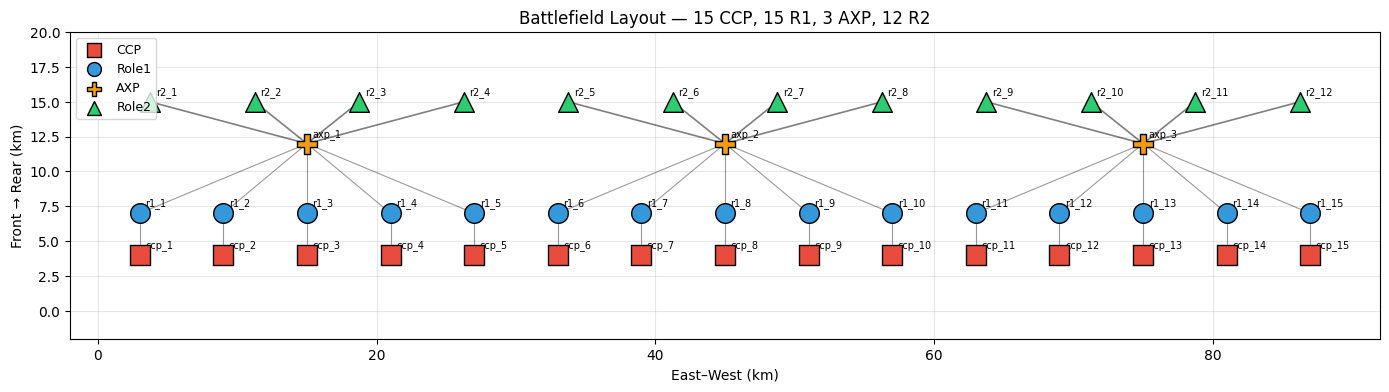

In [111]:
COLORS  = {"CCP": "#e74c3c", "Role1": "#3498db", "AXP": "#f39c12", "Role2": "#2ecc71"}
MARKERS = {"CCP": "s", "Role1": "o", "AXP": "P", "Role2": "^"}

fig, ax = plt.subplots(figsize=(14, 7))
fac_lookup = fac_df.set_index("facility_id")

# CCP → R1
for ccp_id, r1_id in ccp_r1_pairs:
    ccp, r1 = fac_lookup.loc[ccp_id], fac_lookup.loc[r1_id]
    ax.plot([ccp.x, r1.x], [ccp.y, r1.y], "k-", lw=0.8, alpha=0.4)

# R1 → AXP
for r1_id, axp_id in r1_to_axp.items():
    r1, axp = fac_lookup.loc[r1_id], fac_lookup.loc[axp_id]
    ax.plot([r1.x, axp.x], [r1.y, axp.y], "k-", lw=0.8, alpha=0.4)

# AXP → R2
for r2_id, axp_id in r2_to_axp.items():
    r2, axp = fac_lookup.loc[r2_id], fac_lookup.loc[axp_id]
    ax.plot([axp.x, r2.x], [axp.y, r2.y], "k-", lw=1.2, alpha=0.5)

for _, row in fac_df.iterrows():
    ft = row.facility_type
    ax.scatter(row.x, row.y, color=COLORS[ft], marker=MARKERS[ft],
               s=200, edgecolors="black", linewidths=1, zorder=5)
    ax.annotate(row.facility_id, (row.x, row.y),
                xytext=(4, 5), textcoords="offset points", fontsize=7)

handles = [plt.scatter([], [], color=COLORS[ft], marker=MARKERS[ft],
                        s=100, edgecolors="black", label=ft) for ft in COLORS]
ax.legend(handles=handles, loc="upper left", fontsize=9)
ax.set_xlim(-2, FRONTAGE_KM + 2)
ax.set_ylim(-2, Y_R2 + 5)
ax.set_xlabel("East–West (km)")
ax.set_ylabel("Front → Rear (km)")
ax.set_title(f"Battlefield Layout — {N_CCP} CCP, {N_R1} R1, {N_AXP} AXP, {N_R2} R2")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 5 — Export distance matrix & coordinate reference

In [112]:
# Preview of distance matrix — all files are written in the final export cell
dist_df.round(2)

,ccp_1,r1_1,ccp_2,r1_2,ccp_3,r1_3,ccp_4,r1_4,ccp_5,r1_5,...,r2_3,r2_4,r2_5,r2_6,r2_7,r2_8,r2_9,r2_10,r2_11,r2_12
ccp_1,0.00,3.00,6.00,6.71,12.00,12.37,18.00,18.25,24.00,24.19,...,19.21,25.72,32.66,39.80,47.05,54.37,61.74,69.13,76.54,83.97
r1_1,3.00,0.00,6.71,6.00,12.37,12.00,18.25,18.00,24.19,24.00,...,17.67,24.59,31.77,39.08,46.44,53.85,61.27,68.72,76.17,83.63
ccp_2,6.00,6.71,0.00,3.00,6.00,6.71,12.00,12.37,18.00,18.25,...,14.70,20.46,27.08,34.07,41.24,48.51,55.84,63.21,70.61,78.03
r1_2,6.71,6.00,3.00,0.00,6.71,6.00,12.37,12.00,18.25,18.00,...,12.61,19.01,26.01,33.23,40.55,47.92,55.33,62.76,70.21,77.66
ccp_3,12.00,12.37,6.00,6.71,0.00,3.00,6.00,6.71,12.00,12.37,...,11.62,15.73,21.74,28.46,35.50,42.69,49.98,57.32,64.69,72.09
r1_3,12.37,12.00,6.71,6.00,3.00,0.00,6.71,6.00,12.37,12.00,...,8.84,13.80,20.39,27.44,34.69,42.02,49.40,56.82,64.25,71.70
ccp_4,18.00,18.25,12.00,12.37,6.00,6.71,0.00,3.00,6.00,6.71,...,11.23,12.19,16.84,23.04,29.85,36.93,44.14,51.44,58.79,66.17
r1_4,18.25,18.00,12.37,12.00,6.71,6.00,3.00,0.00,6.71,6.00,...,8.31,9.57,15.05,21.77,28.88,36.15,43.49,50.88,58.30,65.74
ccp_5,24.00,24.19,18.00,18.25,12.00,12.37,6.00,6.71,0.00,3.00,...,13.75,11.03,12.91,18.00,24.37,31.25,38.36,45.60,52.91,60.26
r1_5,24.19,24.00,18.25,18.00,12.37,12.00,6.71,6.00,3.00,0.00,...,11.49,8.04,10.47,16.34,23.17,30.32,37.61,44.97,52.36,59.79


## Cell 6 — Build & export all simulation input files

Builds DataFrames for facilities, units, AXPs, ambulances, C2, and both
eligibility matrices, then writes them all to `OUT_BASE`.

In [113]:
# ── Simulation facilities (no AXP) ────────────────────────────────────────────
sim_fac_df = fac_df[fac_df["facility_type"] != "AXP"].copy().reset_index(drop=True)
sim_fac_df["c2_up_id"]      = sim_fac_df["facility_type"].map(
    {"CCP": "C2_CCP_R1", "Role1": "C2_R1_R2", "Role2": None})
sim_fac_df["unload_policy"] = "unload_planned"
sim_fac_df["load_policy"]   = "load_planned"
sim_fac_ids  = sim_fac_df["facility_id"].tolist()
fac_type_map = dict(zip(fac_df["facility_id"], fac_df["facility_type"]))

# ── Units ──────────────────────────────────────────────────────────────────────
unit_rows, uid = [], 1
for _, row in sim_fac_df.iterrows():
    fid, ft = row["facility_id"], row["facility_type"]
    if ft == "Role1":
        for svc, cap, mn, mx in [("DCR", DCR_CAPACITY, DCR_MIN, DCR_MAX),
                                  ("PEC", PEC_CAPACITY, PEC_MIN, PEC_MAX)]:
            unit_rows.append({"unit_id": f"U{uid:03d}", "facility_id": fid,
                               "service_type": svc, "capacity": cap,
                               "service_time_min": mn, "service_time_max": mx})
            uid += 1
    elif ft == "Role2":
        unit_rows.append({"unit_id": f"U{uid:03d}", "facility_id": fid,
                           "service_type": "DCS", "capacity": DCS_CAPACITY,
                           "service_time_type": "normal_by_triage",
                           "service_time_mild_mean":    DCS_MILD_MEAN,
                           "service_time_mild_std":     DCS_MILD_STD,
                           "service_time_severe_mean":  DCS_SEVERE_MEAN,
                           "service_time_severe_std":   DCS_SEVERE_STD})
        uid += 1
units_df = pd.DataFrame(unit_rows)

# ── AXPs ───────────────────────────────────────────────────────────────────────
axp_df = pd.DataFrame(
    [(axp_id, ",".join(r1s)) for axp_id, r1s in sorted(axp_to_r1s.items())],
    columns=["axp_id", "assigned_facility_ids"])

# ── Ambulances ─────────────────────────────────────────────────────────────────
amb_rows, amb_id = [], 1
for _, r1_id in ccp_r1_pairs:          # CCP→R1: stationed at the R1
    for _ in range(CCP_AMBS_PER_R1):
        amb_rows.append({"amb_id": f"AMB{amb_id:03d}", "start_loc_id": r1_id,
                          "capacity": AMB_CAPACITY, "speed_kmh": AMB_SPEED_KMH,
                          "c2_id": "C2_CCP_R1"})
        amb_id += 1
for axp_id in sorted(axp_to_r1s):     # R1→R2: stationed at the AXP
    for _ in range(R1R2_AMBS_PER_AXP):
        amb_rows.append({"amb_id": f"AMB{amb_id:03d}", "start_loc_id": axp_id,
                          "capacity": AMB_CAPACITY, "speed_kmh": AMB_SPEED_KMH,
                          "c2_id": "C2_R1_R2"})
        amb_id += 1
amb_df = pd.DataFrame(amb_rows)

# ── C2 ─────────────────────────────────────────────────────────────────────────
ccp_facs  = [f for f in sim_fac_ids if fac_type_map[f] == "CCP"]
r1_facs   = [f for f in sim_fac_ids if fac_type_map[f] == "Role1"]
ccp_ambs  = amb_df[amb_df.c2_id == "C2_CCP_R1"]["amb_id"].tolist()
r1r2_ambs = amb_df[amb_df.c2_id == "C2_R1_R2"]["amb_id"].tolist()
c2_df = pd.DataFrame([
    ("C2_CCP_R1", ",".join(ccp_facs),  ",".join(ccp_ambs)),
    ("C2_R1_R2",  ",".join(r1_facs),   ",".join(r1r2_ambs)),
], columns=["c2_id", "facility_ids", "ambulance_ids"])

print(f"Facilities: {len(sim_fac_df)}, Units: {len(units_df)}, "
      f"AXPs: {len(axp_df)}, Ambulances: {len(amb_df)}, C2: {len(c2_df)}")

Facilities: 42, Units: 42, AXPs: 3, Ambulances: 57, C2: 2


In [114]:
ccp_to_r1  = dict(ccp_r1_pairs)

def make_fac_eligibility(loose=False):
    dm = pd.DataFrame(0, index=sim_fac_ids, columns=sim_fac_ids)
    for src in sim_fac_ids:
        if fac_type_map[src] == "CCP":
            for dst in sim_fac_ids:
                if fac_type_map[dst] != "Role1": continue
                dm.loc[src, dst] = 1 if (loose or ccp_to_r1.get(src) == dst) else 0
        elif fac_type_map[src] == "Role1":
            src_axp = r1_to_axp[src]
            for dst in sim_fac_ids:
                if fac_type_map[dst] != "Role2": continue
                dm.loc[src, dst] = 1 if (loose or r2_to_axp.get(dst) == src_axp) else 0
    return dm

def make_amb_eligibility(loose=False):
    dm = pd.DataFrame(0, index=amb_df["amb_id"].tolist(), columns=sim_fac_ids)
    for _, arow in amb_df.iterrows():
        aid, c2id, start = arow["amb_id"], arow["c2_id"], arow["start_loc_id"]
        if c2id == "C2_CCP_R1":
            if loose:
                for fid in sim_fac_ids:
                    if fac_type_map[fid] in ("CCP", "Role1"):
                        dm.loc[aid, fid] = 1
            else:
                ccp_pair = next((c for c, r in ccp_r1_pairs if r == start), None)
                for fid in [start, ccp_pair]:
                    if fid and fid in sim_fac_ids:
                        dm.loc[aid, fid] = 1
        elif c2id == "C2_R1_R2":
            axp_id  = start   # ambulance stationed at AXP
            axp_r1s = axp_to_r1s[axp_id]
            axp_r2s = [r2 for r2, a in r2_to_axp.items() if a == axp_id]
            for fid in sim_fac_ids:
                if loose:
                    if fac_type_map[fid] in ("Role1", "Role2"):
                        dm.loc[aid, fid] = 1
                else:
                    if fid in axp_r1s or fid in axp_r2s:
                        dm.loc[aid, fid] = 1
    return dm

fac_strict = make_fac_eligibility(loose=False)
fac_loose  = make_fac_eligibility(loose=True)
amb_strict = make_amb_eligibility(loose=False)
amb_loose  = make_amb_eligibility(loose=True)
print("Eligibility matrices built.")

Eligibility matrices built.


In [ ]:
def _out(subpath):
    p = OUT_BASE / subpath
    p.parent.mkdir(parents=True, exist_ok=True)
    return p

# ── Spawn map (uniform rate per CCP / R1) ─────────────────────────────────────
bcas_rate_per_ccp = CAS_BCAS_RATE   # full rate; generator groups CCPs into one stream
dnbi_rate_per_r1  = CAS_DNBI_RATE    # same for DNBI
spawn_map = {}
for ccp_id, r1_id in ccp_r1_pairs:
    spawn_map[ccp_id] = {"labels": ["T1_BCAS","T2_BCAS","T3_BCAS","KIA_BCAS","MIA_BCAS"],
                          "rate": bcas_rate_per_ccp}
    spawn_map[r1_id]  = {"labels": ["T1_DNBI","T2_DNBI","T3_DNBI"],
                          "rate": dnbi_rate_per_r1}

config_dict = {
    "par_total": TOTAL_PAR, "n_days": 7, "waves_per_day": 3,
    "wave_duration_min": 30, "seed": 42,
    "spawn_map": spawn_map,
}

# ── Facilities export — include real coordinates for visualization ──────────────
sim_fac_df["x_km"] = sim_fac_df["x"]
sim_fac_df["y_km"] = sim_fac_df["y"]

# ── Write all files ────────────────────────────────────────────────────────────
exports = [
    (_out(f"components/distances/distance_matrix_{SUFFIX}.xlsx"),
     lambda p: dist_df.round(4).to_excel(p)),
    (_out(f"components/distances/coordinates_{SUFFIX}.xlsx"),
     lambda p: fac_df[["facility_id","facility_type","x","y"]].to_excel(p, index=False)),
    (_out(f"components/facilities/facilities_{SUFFIX}.xlsx"),
     lambda p: sim_fac_df[["facility_id","facility_type","c2_up_id",
                            "unload_policy","load_policy",
                            "x_km","y_km"]].to_excel(p, index=False)),
    (_out(f"components/units/units_{SUFFIX}.xlsx"),
     lambda p: units_df.to_excel(p, index=False)),
    (_out(f"components/AXPs/axp_{SUFFIX}.xlsx"),
     lambda p: axp_df.to_excel(p, index=False)),
    (_out(f"components/ambulances/amb_{SUFFIX}.xlsx"),
     lambda p: amb_df.to_excel(p, index=False)),
    (_out(f"components/c2/c2_{SUFFIX}.xlsx"),
     lambda p: c2_df.to_excel(p, index=False)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: fac_strict.to_excel(p)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: fac_loose.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: amb_strict.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: amb_loose.to_excel(p)),
]

for path, writer in exports:
    writer(path)
    print(f"  ✓ {path.relative_to(OUT_BASE)}")

cfg_path = _out(f"casualty_generation_settings/sampling_settings/config_{SUFFIX}.txt")
with open(cfg_path, "w", encoding="utf-8") as f:
    yaml.dump(config_dict, f, default_flow_style=False, allow_unicode=True)
print(f"  ✓ {cfg_path.relative_to(OUT_BASE)}")
print("Done.")

In [ ]:
# ── Scenario YAML is NOT generated here ──────────────────────────────────────
# The scenario YAML (e.g. scenario_meisner_strict_short_1.yaml) must reference
# the files above.  Update SUFFIX there if you change it here.
